# Project 1: Loan Approval Prediction System 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/pawaderahul/Loan-Approval-Prediction/main/train.csv"

df = pd.read_csv(url)

print(df.head())
print(df.shape)

    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

In [2]:
df.drop("Loan_ID", axis=1, inplace=True, errors="ignore")
df.dropna(inplace=True)

print(df.isnull().sum())
print(df.shape)

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64
(480, 12)


In [3]:
from sklearn.preprocessing import LabelEncoder

df = df.copy()

for col in df.select_dtypes(include="object").columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

df.head()

C:\Users\anshu\AppData\Local\Temp\ipykernel_15692\1982561636.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2,1
5,1,1,2,0,1,5417,4196.0,267.0,360.0,1.0,2,1


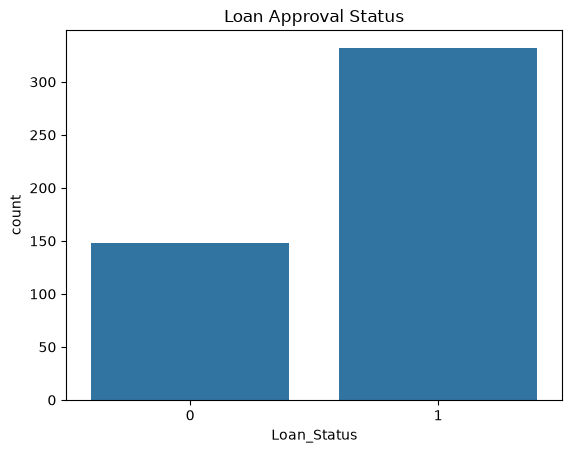

In [4]:
sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approval Status")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [6]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [7]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8229166666666666


In [8]:
sample = X_test.iloc[[0]]
prediction = model.predict(sample)

if prediction[0] == 1:
    print("Loan Approved")
else:
    print("Loan Not Approved")

Loan Approved


# Project 2: Disease Prediction System 

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/kinjal-nigam/ML_Project/main/Training.csv"

df = pd.read_csv(url)

print(df.head())
print(df.shape)

   itching  skin_rash  nodal_skin_eruptions  continuous_sneezing  shivering  \
0        1          1                     1                    0          0   
1        0          1                     1                    0          0   
2        1          0                     1                    0          0   
3        1          1                     0                    0          0   
4        1          1                     1                    0          0   

   chills  joint_pain  stomach_pain  acidity  ulcers_on_tongue  ...  scurring  \
0       0           0             0        0                 0  ...         0   
1       0           0             0        0                 0  ...         0   
2       0           0             0        0                 0  ...         0   
3       0           0             0        0                 0  ...         0   
4       0           0             0        0                 0  ...         0   

   skin_peeling  silver_like_dusting  

In [10]:
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
df = df.dropna()

print("Missing values:", df.isnull().sum().sum())
print("Dataset shape:", df.shape)

Missing values: 0
Dataset shape: (4920, 133)


prognosis
Fungal infection       120
Allergy                120
GERD                   120
Chronic cholestasis    120
Drug Reaction          120
Peptic ulcer diseae    120
AIDS                   120
Diabetes               120
Gastroenteritis        120
Bronchial Asthma       120
Name: count, dtype: int64


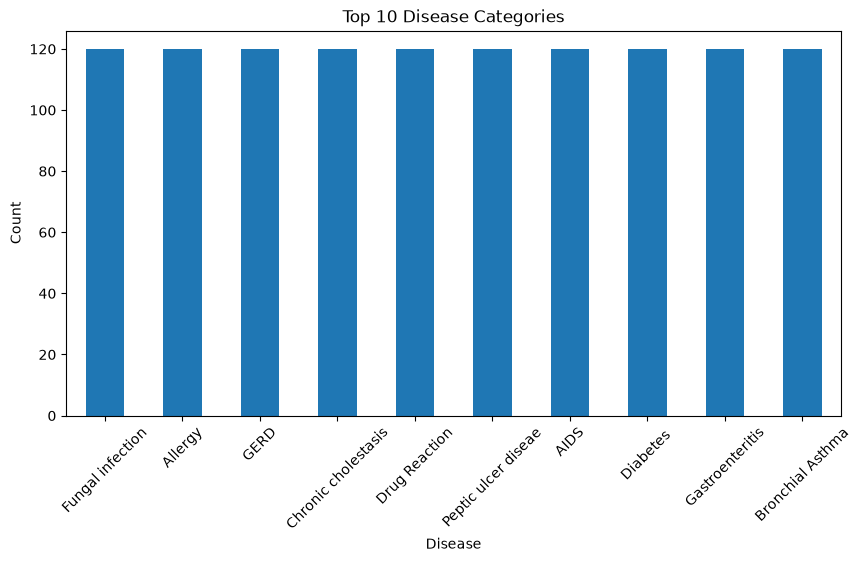

In [11]:
print(df["prognosis"].value_counts().head(10))

plt.figure(figsize=(10, 5))
df["prognosis"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Disease Categories")
plt.xlabel("Disease")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop("prognosis", axis=1)
y = df["prognosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Naive Bayes": BernoulliNB()
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy

    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

Decision Tree Accuracy: 100.0 %
Random Forest Accuracy: 100.0 %
Naive Bayes Accuracy: 100.0 %


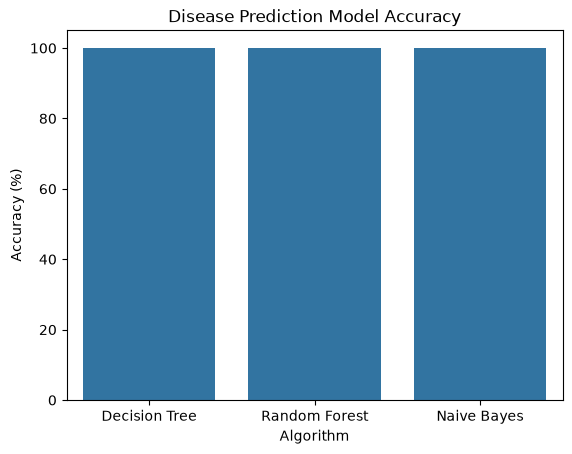

In [14]:
accuracy_df = pd.DataFrame({
    "Algorithm": list(results.keys()),
    "Accuracy": [v * 100 for v in results.values()]
})

sns.barplot(data=accuracy_df, x="Algorithm", y="Accuracy")
plt.title("Disease Prediction Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.show()

In [15]:
best_name = max(results, key=results.get)
best_model = models[best_name]

sample = X_test.iloc[[0]]
prediction = best_model.predict(sample)

print("Best Model:", best_name)
print("Predicted Disease:", prediction[0])
print("Actual Disease:", y_test.iloc[0])

Best Model: Decision Tree
Predicted Disease: Hypertension 
Actual Disease: Hypertension 


In [16]:
print("Model Comparison Results")

for name, accuracy in results.items():
    print(f"{name}: {accuracy * 100:.2f}%")

print("\nBest Algorithm:", best_name)
print("Best Accuracy:", round(results[best_name] * 100, 2), "%")

Model Comparison Results
Decision Tree: 100.00%
Random Forest: 100.00%
Naive Bayes: 100.00%

Best Algorithm: Decision Tree
Best Accuracy: 100.0 %
